# Airline fleet allocation in East Asia

**Question:** How do airlines combine aircraft size and flight frequency, and which carrier–route combinations differ from a descriptive market benchmark?

This study combines U.S. DOT T-100 international segment data with a Taiwan CAA case study for 2019 and 2023–2025. It emphasizes auditable reporting corrections, departure-weighted comparisons, and the limits of interpreting seat capacity as demand or profitability.

The main findings are summarized in the [README](../README.md). [Data instructions](../data/README.md) describe each source and required filename.

## 1. Setup and scope

Install `requirements.txt` before running this notebook. Read inputs from `data/raw/` and the bundled public aircraft-code reference; write aggregate results to `results/` and figures to `figures/`.

The main market is scheduled passenger service between the continental U.S. and selected East/Southeast Asian countries. Both directions are included. Gauge is seats divided by performed departures; passenger load factor is passengers divided by seats. The model observation is one carrier–route–direction–month.

In [1]:
from pathlib import Path
import sys

# Locate the project from either the root folder or notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src" / "config.py").is_file():
    raise FileNotFoundError("Open this notebook from the project folder or notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from src.config import INPUTS, RESULT_DIR, FIGURE_DIR, validate_inputs
from src.data import load_t100_panel, load_taiwan_data
from src.models import (sum_with_missing, fit_weighted_gauge_model,
                        coefficient_table, aggregate_expected_gauge)

validate_inputs()
RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
assets_dir = FIGURE_DIR
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

## 2. Audit reported aircraft and freight

The pipeline removes explicitly freighter-coded rows from the passenger sample and retains reported aircraft fields beside analysis fields. The author manually reviewed the relevant seat counts and carrier fleets:

- Singapore Airlines A380-coded rows averaging 250–300 seats per departure are assigned to the 777-300ER family.
- Singapore Airlines and Asiana A350-coded rows averaging at least 400 seats per departure are assigned to A380, only in the four studied years.

These are carrier-specific manual inferences. The seat threshold is not a universal aircraft-identification rule; the data do not verify tail numbers. SQ's retired 747 passenger fleet was part of the author's contextual review. Thresholds preserve the original analysis; correction logs show every affected year and route.

Broad family seat ranges and within-carrier deviations flag remaining questionable pairs. Reviewed SQ A350 ULR and ANA premium-heavy 777 configurations are retained. Unresolved pairs are excluded from the model, but remain in descriptive market totals; these are different sample definitions.

In [2]:
audit = load_t100_panel(INPUTS)
panel = audit["panel"]
display(audit["t100_inventory"])
display(audit["qc_summary"])
display(audit["sq_correction_summary"].head(12))
display(audit["a350_to_a380_log"].head(12))

,YEAR,rows,months,carriers,origin_airports,destination_airports,aircraft_codes,aircraft_lookup_match
0,2019,92371,12,276,911,894,136,1.000
1,2023,102133,12,250,989,948,129,1.000
2,2024,108801,12,262,963,930,137,1.000
3,2025,112306,12,256,983,943,130,1.000


,rule,count
0,Explicit freighter rows removed,14
1,SQ low-seat A380-coded rows analyzed as 777-300ER,120
2,A350-coded 400+ seat rows analyzed as A380 family,88
3,Carrier-years with unreliable mechanical freight,3
4,Confirmed premium/ULR configurations retained,600
5,Remaining unresolved aircraft-seat rows exclud...,394


,YEAR,ROUTE,AIRCRAFT_TYPE_REPORTED,AIRCRAFT_DESCRIPTION_REPORTED,AIRCRAFT_DESCRIPTION_ANALYSIS,rows,departures,seats,min_reported_gauge,median_reported_gauge,max_reported_gauge
0,2023,LAX–NRT,882,Airbus Industrie A380-800,Boeing 777-300ER,18,550.000,"145,200.000",264.000,264.000,264.000
1,2023,LAX–SIN,882,Airbus Industrie A380-800,Boeing 777-300ER,14,428.000,"112,992.000",264.000,264.000,264.000
2,2024,LAX–NRT,882,Airbus Industrie A380-800,Boeing 777-300ER,22,666.000,"175,824.000",264.000,264.000,264.000
3,2024,LAX–SIN,882,Airbus Industrie A380-800,Boeing 777-300ER,22,666.000,"175,824.000",264.000,264.000,264.000
4,2025,LAX–NRT,882,Airbus Industrie A380-800,Boeing 777-300ER,22,658.000,"173,976.000",264.000,264.000,274.154
5,2025,LAX–SIN,882,Airbus Industrie A380-800,Boeing 777-300ER,22,658.000,"174,240.000",264.000,264.000,274.154


,YEAR,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,ROUTE,AIRCRAFT_TYPE_REPORTED,AIRCRAFT_DESCRIPTION_REPORTED,AIRCRAFT_DESCRIPTION_ANALYSIS,rows,departures,seats,min_gauge,median_gauge,max_gauge
5,2024,OZ,Asiana Airlines Inc.,LAX–ICN,359,Airbus Industrie A350-900,Airbus A380-800 (manual carrier-specific infer...,18,550.000,"271,150.000",493.000,493.000,493.000
6,2024,SQ,Singapore Airlines Ltd.,SFO–SIN,359,Airbus Industrie A350-900,Airbus A380-800 (manual carrier-specific infer...,18,548.000,"227,236.000",414.000,415.000,415.000
12,2025,SQ,Singapore Airlines Ltd.,SFO–SIN,359,Airbus Industrie A350-900,Airbus A380-800 (manual carrier-specific infer...,15,438.000,"181,470.000",414.000,414.000,415.000
8,2025,OZ,Asiana Airlines Inc.,LAX–ICN,359,Airbus Industrie A350-900,Airbus A380-800 (manual carrier-specific infer...,13,397.000,"191,178.000",453.452,493.000,493.000
0,2019,OZ,Asiana Airlines Inc.,JFK–ICN,359,Airbus Industrie A350-900,Airbus A380-800 (manual carrier-specific infer...,8,243.000,"115,425.000",415.000,495.000,495.000
7,2025,OZ,Asiana Airlines Inc.,JFK–ICN,359,Airbus Industrie A350-900,Airbus A380-800 (manual carrier-specific infer...,2,186.000,"82,870.000",421.796,445.538,469.280
3,2023,SQ,Singapore Airlines Ltd.,SFO–SIN,359,Airbus Industrie A350-900,Airbus A380-800 (manual carrier-specific infer...,4,122.000,"49,864.000",403.613,408.806,414.000
4,2024,OZ,Asiana Airlines Inc.,JFK–ICN,359,Airbus Industrie A350-900,Airbus A380-800 (manual carrier-specific infer...,3,106.000,"46,028.000",405.652,441.419,471.862
1,2019,OZ,Asiana Airlines Inc.,LAX–ICN,359,Airbus Industrie A350-900,Airbus A380-800 (manual carrier-specific infer...,2,62.000,"30,548.000",492.581,492.710,492.839
2,2023,OZ,Asiana Airlines Inc.,JFK–ICN,359,Airbus Industrie A350-900,Airbus A380-800 (manual carrier-specific infer...,2,61.000,"27,368.000",441.419,448.776,456.133


### Freight quality

A carrier-year is flagged when at least 12 eligible rows exist and at least 60% report 199.5–200.5 lb of freight per passenger. The affected Starlux years show a mechanical pattern that is unsuitable as an independent cargo measure. Their passenger and capacity records remain; their freight is missing in cargo models. Passing this screen does not establish perfect freight measurement.

In [3]:
display(audit["freight_reporting_audit"].query("unreliable_freight"))

,YEAR,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,rows,departures,eligible_rows,mechanical_200lb_rows,reported_freight_tonnes,mechanical_200lb_share,unreliable_freight,quality_reason
47,2023,JX,STARLUX AIRLINES,32,559.000,31,21,"13,835.192",0.677,True,Freight mechanically follows approximately 200...
73,2024,JX,STARLUX AIRLINES,60,"1,506.000",60,60,"33,164.808",1.000,True,Freight mechanically follows approximately 200...
100,2025,JX,STARLUX AIRLINES,82,"2,422.000",81,69,"48,644.645",0.852,True,Freight mechanically follows approximately 200...


## 3. Market recovery and fleet composition

Compare departures, capacity, and passengers before interpreting changes in aircraft-family shares.

Continental U.S.-Asia widebody market:
Aircraft-family departure shares:


,YEAR,departures,seats,passengers,seats_per_departure,passenger_load_factor
0,2019,"113,532.000","32,922,216.000","27,098,870.000",289.982,0.823
1,2023,"76,167.000","21,672,237.000","18,211,236.000",284.536,0.840
2,2024,"94,448.000","27,307,107.000","22,531,724.000",289.123,0.825
3,2025,"102,388.000","29,682,041.000","24,320,217.000",289.898,0.819


YEAR,2019,2025
AIRCRAFT_FAMILY,,
777,0.564,0.416
787,0.215,0.281
A350,0.111,0.236
A380,0.039,0.028


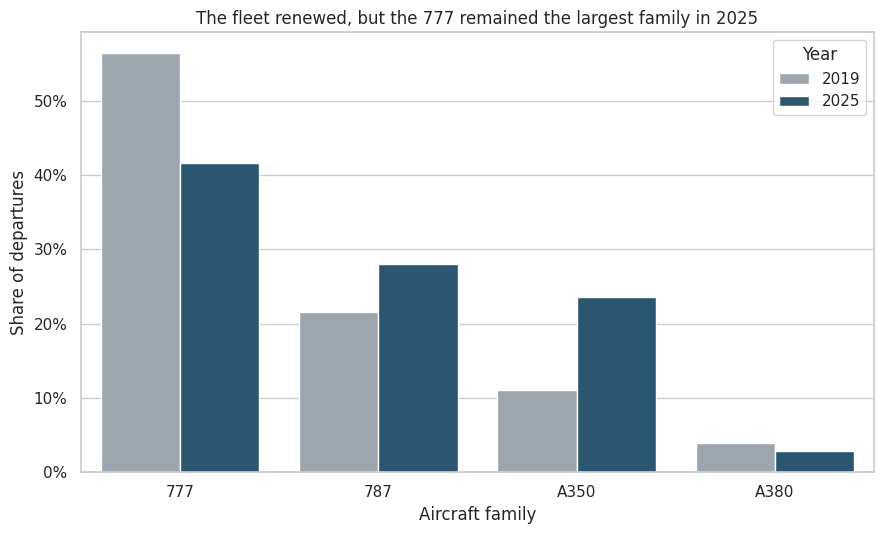

In [4]:
continental = panel.loc[
    panel["US_MARKET"].eq("Continental U.S.") & panel["WIDEBODY"]
].copy()

annual_continental = (
    continental.groupby("YEAR", observed=True)
    .agg(
        departures=("DEPARTURES_PERFORMED", "sum"),
        seats=("SEATS", "sum"),
        passengers=("PASSENGERS", "sum"),
        routes=("ROUTE", "nunique"),
        carriers=("UNIQUE_CARRIER", "nunique"),
    )
    .reset_index()
)
annual_continental["seats_per_departure"] = (
    annual_continental["seats"] / annual_continental["departures"]
)
annual_continental["passenger_load_factor"] = (
    annual_continental["passengers"] / annual_continental["seats"]
)

benchmark = annual_continental.loc[
    annual_continental["YEAR"].isin([2019, 2025])
].copy()
for column in ["departures", "seats", "passengers", "seats_per_departure"]:
    base = benchmark.loc[benchmark["YEAR"].eq(2019), column].iloc[0]
    benchmark[f"{column}_index_2019_100"] = 100 * benchmark[column] / base

family_year = (
    continental.groupby(["YEAR", "AIRCRAFT_FAMILY"], observed=True)
    .agg(departures=("DEPARTURES_PERFORMED", "sum"))
    .reset_index()
)
family_year["departure_share"] = family_year["departures"] / family_year.groupby(
    "YEAR", observed=True
)["departures"].transform("sum")

family_focus = family_year.loc[
    family_year["AIRCRAFT_FAMILY"].isin(["777", "787", "A350", "A380"])
    & family_year["YEAR"].isin([2019, 2025])
].copy()

print("Continental U.S.-Asia widebody market:")
display(
    annual_continental[[
        "YEAR", "departures", "seats", "passengers",
        "seats_per_departure", "passenger_load_factor",
    ]]
)
print("Aircraft-family departure shares:")
display(
    family_focus.pivot(index="AIRCRAFT_FAMILY", columns="YEAR", values="departure_share")
    .sort_values(2025, ascending=False)
)



fig, ax = plt.subplots(figsize=(9, 5.5))
plot_data = family_focus.copy()
sns.barplot(
    data=plot_data,
    x="AIRCRAFT_FAMILY",
    y="departure_share",
    hue="YEAR",
    order=["777", "787", "A350", "A380"],
    palette=["#9AA5B1", "#1F5A7A"],
    ax=ax,
)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax.set(
    title="The fleet renewed, but the 777 remained the largest family in 2025",
    xlabel="Aircraft family",
    ylabel="Share of departures",
)
ax.legend(title="Year")
fig.tight_layout()
fig.savefig(assets_dir / "aircraft_family_2019_2025.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. Regional case: Taipei–Hong Kong

Taiwan CAA sheet 53-1 reports flights, seats, and passengers by airline and destination. Reconcile inbound and outbound counts before comparing years. Aircraft types are unavailable in this source; gauge is an average.

In [5]:
taiwan = load_taiwan_data(INPUTS)
tpe_hkg_airline_year = taiwan["tpe_hkg_airline_year"]
tpe_hkg_2019_vs_2025 = taiwan["tpe_hkg_2019_vs_2025"]
display(taiwan["tpe_quality"])
display(taiwan["tpe_hkg_total"])
display(tpe_hkg_2019_vs_2025)

,year,rows,destinations,airlines,flights,seats,passengers,flight_balance_errors,computed_load_factor
0,2019,327,134,65,239098,59887682,48446179,0,0.809
1,2023,258,104,56,173465,45337575,35277452,0,0.778
2,2024,271,102,57,220364,56322003,44906019,0,0.797
3,2025,275,108,57,232792,59739406,47837164,0,0.801


,year,flights,seats,passengers,seats_per_flight,passenger_load_factor
0,2019,26911,7823757,6109841,290.727,0.781
1,2023,17320,4509072,3489592,260.339,0.774
2,2024,26346,6648989,4393422,252.372,0.661
3,2025,27044,6814119,4905000,251.964,0.720


,airline_zh,airline,flights_2019,seats_per_flight_2019,passenger_load_factor_2019,empty_seats_per_flight_2019,flights_2025,seats_per_flight_2025,passenger_load_factor_2025,empty_seats_per_flight_2025,flight_change_pct,gauge_change,load_factor_change_pp
0,中華,China Airlines,6309,274.890,0.743,70.595,4853,185.335,0.703,54.968,-0.231,-89.554,-3.977
1,長榮,EVA Air,5765,244.462,0.800,48.945,5276,270.001,0.638,97.695,-0.085,25.539,-16.162
2,國泰,Cathay Pacific,10746,327.673,0.777,73.123,8423,315.781,0.699,95.067,-0.216,-11.892,-7.789
3,香港,Hong Kong Airlines,2914,291.614,0.851,43.346,2694,206.112,0.863,28.167,-0.075,-85.501,1.198


### Incumbent carrier comparisons

The chart compares four carriers present in both years. The route-total table includes all observed carriers.

,year,airline,flights,seats_per_flight,computed_load_factor,empty_seats_per_flight
88,2019,Cathay Pacific,10746,327.673,0.777,73.123
949,2025,Cathay Pacific,8423,315.781,0.699,95.067
86,2019,China Airlines,6309,274.890,0.743,70.595
946,2025,China Airlines,4853,185.335,0.703,54.968
87,2019,EVA Air,5765,244.462,0.800,48.945
948,2025,EVA Air,5276,270.001,0.638,97.695
90,2019,Hong Kong Airlines,2914,291.614,0.851,43.346
950,2025,Hong Kong Airlines,2694,206.112,0.863,28.167


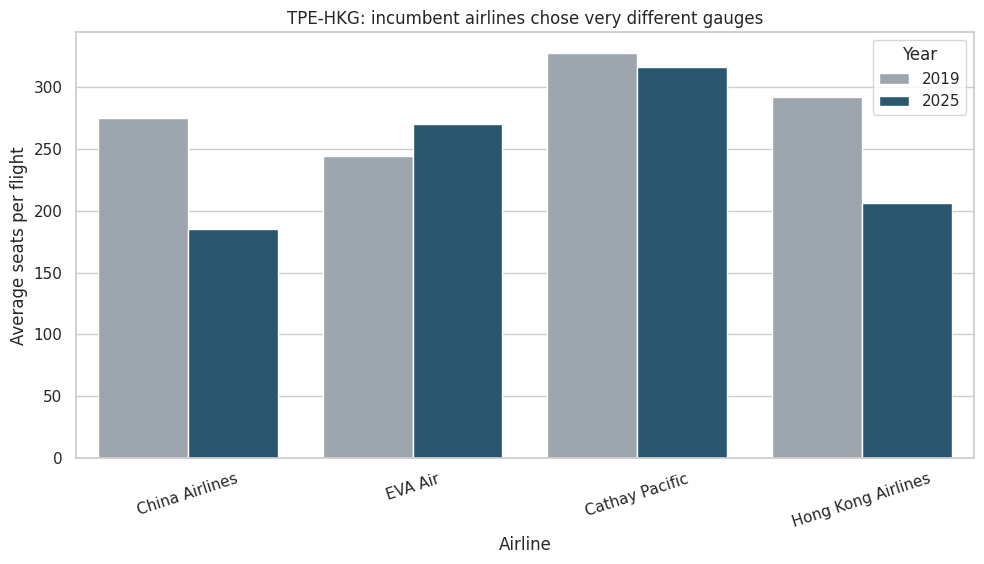

In [6]:
hkg_selected = tpe_hkg_airline_year.loc[
    tpe_hkg_airline_year["year"].isin([2019, 2025])
    & tpe_hkg_airline_year["airline"].isin(
        ["Cathay Pacific", "China Airlines", "EVA Air", "Hong Kong Airlines"]
    )
].copy()

display(
    hkg_selected[[
        "year", "airline", "flights", "seats_per_flight",
        "computed_load_factor", "empty_seats_per_flight",
    ]].sort_values(["airline", "year"])
)

fig, ax = plt.subplots(figsize=(10, 5.8))
sns.barplot(
    data=hkg_selected,
    x="airline",
    y="seats_per_flight",
    hue="year",
    palette=["#9AA5B1", "#1F5A7A"],
    ax=ax,
)
ax.set(
    title="TPE-HKG: incumbent airlines chose very different gauges",
    xlabel="Airline",
    ylabel="Average seats per flight",
)
ax.tick_params(axis="x", rotation=18)
ax.legend(title="Year")
fig.tight_layout()
fig.savefig(assets_dir / "tpe_hkg_gauge_2019_2025.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Build the descriptive benchmark sample

Keep continental U.S. widebody records without unresolved aircraft–seat flags. Require at least ten departures per carrier–route–direction–month and at least two carriers on the route over the pooled study period.

In [7]:
valid_model_rows = panel.loc[
    panel["US_MARKET"].eq("Continental U.S.")
    & panel["WIDEBODY"]
    & ~panel["UNRESOLVED_AIRCRAFT_PAIR"]
].copy()

MONTHLY_KEYS = [
    "YEAR", "MONTH", "DATE", "UNIQUE_CARRIER", "UNIQUE_CARRIER_NAME",
    "US_AIRPORT", "ASIA_AIRPORT", "ASIA_COUNTRY", "ROUTE", "DIRECTION",
]

monthly_model_panel = (
    valid_model_rows.groupby(MONTHLY_KEYS, observed=True)
    .agg(
        departures=("DEPARTURES_PERFORMED", "sum"),
        seats=("SEATS", "sum"),
        passengers=("PASSENGERS", "sum"),
        freight_tonnes=("FREIGHT_TONNES_RELIABLE", sum_with_missing),
        reliable_freight_departures=("RELIABLE_FREIGHT_DEPARTURES", "sum"),
        distance_miles=("DISTANCE", "median"),
        aircraft_families=("AIRCRAFT_FAMILY", "nunique"),
    )
    .reset_index()
)

monthly_model_panel["seats_per_departure"] = (
    monthly_model_panel["seats"] / monthly_model_panel["departures"]
)
monthly_model_panel["passenger_load_factor"] = (
    monthly_model_panel["passengers"] / monthly_model_panel["seats"]
)
monthly_model_panel["freight_reliable_departure_share"] = (
    monthly_model_panel["reliable_freight_departures"]
    / monthly_model_panel["departures"]
)
monthly_model_panel["freight_tonnes_per_departure"] = (
    monthly_model_panel["freight_tonnes"]
    / monthly_model_panel["reliable_freight_departures"].replace(0, np.nan)
)

monthly_model_panel = monthly_model_panel.loc[
    monthly_model_panel["departures"].ge(10)
].copy()

route_carrier_counts = (
    monthly_model_panel.groupby("ROUTE", observed=True)["UNIQUE_CARRIER"]
    .nunique()
)
competitive_routes = route_carrier_counts.loc[
    route_carrier_counts.ge(2)
].index
monthly_model_panel = monthly_model_panel.loc[
    monthly_model_panel["ROUTE"].isin(competitive_routes)
].copy()

monthly_model_panel["log_monthly_departures"] = np.log(
    monthly_model_panel["departures"]
)
monthly_model_panel["YEAR_CAT"] = monthly_model_panel["YEAR"].astype(str)
monthly_model_panel["MONTH_CAT"] = monthly_model_panel["MONTH"].astype(str)

model_sample_summary = (
    monthly_model_panel.groupby("YEAR", observed=True)
    .agg(
        monthly_observations=("YEAR", "size"),
        carriers=("UNIQUE_CARRIER", "nunique"),
        routes=("ROUTE", "nunique"),
        departures=("departures", "sum"),
        seats=("seats", "sum"),
    )
    .reset_index()
)
model_sample_summary["average_gauge"] = (
    model_sample_summary["seats"] / model_sample_summary["departures"]
)

display(model_sample_summary)

,YEAR,monthly_observations,carriers,routes,departures,seats,average_gauge
0,2019,2169,16,42,"76,895.000","22,511,624.000",292.758
1,2023,1548,16,37,"54,683.000","15,614,425.000",285.544
2,2024,1851,17,36,"67,585.000","19,765,824.000",292.459
3,2025,2031,18,37,"74,474.000","21,673,724.000",291.024


## 6. Fit departure-weighted models

Regress seats per departure on log monthly departures plus route, direction, year, and month indicators. A second specification adds carrier indicators. Passenger count and load factor are excluded because they share accounting relationships with capacity.

All metrics below describe **in-sample fit**. There is no holdout evaluation and this is not a forecasting model. Residuals indicate differences from this benchmark, not excess capacity or inefficient assignments.

In [8]:
BASE_CATEGORICAL = ["ROUTE", "DIRECTION", "YEAR_CAT", "MONTH_CAT"]
BASE_NUMERIC = ["log_monthly_departures"]

market_model, market_prediction, market_metrics = fit_weighted_gauge_model(
    monthly_model_panel,
    BASE_CATEGORICAL,
    BASE_NUMERIC,
    "Market benchmark",
)
airline_model, airline_prediction, airline_metrics = fit_weighted_gauge_model(
    monthly_model_panel,
    BASE_CATEGORICAL + ["UNIQUE_CARRIER"],
    BASE_NUMERIC,
    "Airline-adjusted diagnostic",
)

monthly_model_panel["expected_gauge_market"] = market_prediction
monthly_model_panel["residual_market"] = (
    monthly_model_panel["seats_per_departure"]
    - monthly_model_panel["expected_gauge_market"]
)
monthly_model_panel["expected_gauge_airline_adjusted"] = airline_prediction
monthly_model_panel["residual_airline_adjusted"] = (
    monthly_model_panel["seats_per_departure"]
    - monthly_model_panel["expected_gauge_airline_adjusted"]
)

model_summary = pd.DataFrame([market_metrics, airline_metrics])
display(model_summary)

,model,evaluation,observations,departures,weighted_r_squared,weighted_mae_seats,weighted_rmse_seats
0,Market benchmark,"In-sample, departure-weighted",7599,"273,637.000",0.658,24.416,32.810
1,Airline-adjusted diagnostic,"In-sample, departure-weighted",7599,"273,637.000",0.789,18.131,25.766


### Frequency association

The log-frequency coefficient is descriptive. Doubling frequency corresponds to the coefficient multiplied by `log(2)`.

In [9]:
main_coefficients = coefficient_table(
    market_model, "Market benchmark"
)
frequency_coefficient = main_coefficients.loc[
    main_coefficients["feature"].eq("log_monthly_departures"),
    "coefficient_seats",
].iloc[0]
frequency_doubling_effect = frequency_coefficient * np.log(2)

print(
    "Associated change in expected gauge when monthly frequency doubles: "
    f"{frequency_doubling_effect:,.1f} seats per departure"
)
display(main_coefficients)

Associated change in expected gauge when monthly frequency doubles: -10.5 seats per departure


,model,feature,coefficient_seats
0,Market benchmark,YEAR_CAT_2023,-7.044
1,Market benchmark,YEAR_CAT_2024,-3.246
2,Market benchmark,YEAR_CAT_2025,-4.320
3,Market benchmark,log_monthly_departures,-15.103


## 7. Annual route–carrier comparisons

Aggregate residuals using departure weights. For 2025 displays, require at least 100 departures, eight operating months, and two carriers on the route in that year.

In [10]:
annual_market_residuals = aggregate_expected_gauge(
    monthly_model_panel,
    "expected_gauge_market",
    "residual_market",
)
annual_airline_adjusted_residuals = aggregate_expected_gauge(
    monthly_model_panel,
    "expected_gauge_airline_adjusted",
    "residual_airline_adjusted",
)

competitors_by_route_year = (
    monthly_model_panel.groupby(["YEAR", "ROUTE"], observed=True)[
        "UNIQUE_CARRIER"
    ]
    .nunique()
    .reset_index(name="competing_carriers")
)
annual_market_residuals = annual_market_residuals.merge(
    competitors_by_route_year,
    on=["YEAR", "ROUTE"],
    how="left",
    validate="many_to_one",
)
annual_airline_adjusted_residuals = annual_airline_adjusted_residuals.merge(
    competitors_by_route_year,
    on=["YEAR", "ROUTE"],
    how="left",
    validate="many_to_one",
)

residual_rankings_2025 = annual_market_residuals.loc[
    annual_market_residuals["YEAR"].eq(2025)
    & annual_market_residuals["departures"].ge(100)
    & annual_market_residuals["months_operated"].ge(8)
    & annual_market_residuals["competing_carriers"].ge(2)
].copy()

largest_gauge_residuals_2025 = residual_rankings_2025.nlargest(
    15, "gauge_residual"
)
smallest_gauge_residuals_2025 = residual_rankings_2025.nsmallest(
    15, "gauge_residual"
)

print("Largest positive residuals: larger gauge than the market benchmark")
display(largest_gauge_residuals_2025)
print("Largest negative residuals: smaller gauge than the market benchmark")
display(smallest_gauge_residuals_2025)

Largest positive residuals: larger gauge than the market benchmark
Largest negative residuals: smaller gauge than the market benchmark


,YEAR,ROUTE,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,US_AIRPORT,ASIA_AIRPORT,departures,seats,passengers,expected_seat_capacity,residual_seat_capacity,months_operated,distance_miles,actual_gauge,expected_gauge,gauge_residual,passenger_load_factor,competing_carriers
298,2025,ORD–HND,UA,United Air Lines Inc.,ORD,HND,725.000,"230,325.000","197,493.000","182,328.117","47,996.883",12,"6,305.000",317.690,251.487,66.203,0.857,3
308,2025,SEA–NRT,HA,Hawaiian Airlines Inc.,SEA,NRT,463.000,"128,714.000","100,156.000","98,738.176","29,975.824",8,"4,768.000",278.000,213.257,64.743,0.778,2
276,2025,LAX–HND,UA,United Air Lines Inc.,LAX,HND,731.000,"231,665.000","207,515.000","186,601.658","45,063.342",12,"5,487.000",316.915,255.269,61.646,0.896,5
333,2025,SFO–SIN,SQ,Singapore Airlines Ltd.,SFO,SIN,653.000,"216,085.000","194,730.000","176,800.948","39,284.052",11,"8,440.000",330.911,270.752,60.159,0.901,2
328,2025,SFO–NRT,UA,United Air Lines Inc.,SFO,NRT,737.000,"228,976.000","189,625.000","190,706.529","38,269.471",12,"5,124.000",310.687,258.761,51.926,0.828,4
302,2025,SEA–HND,DL,Delta Air Lines Inc.,SEA,HND,725.000,"212,608.000","190,016.000","178,267.481","34,340.519",12,"4,803.000",293.252,245.886,47.366,0.894,2
263,2025,JFK–HND,AA,American Airlines Inc.,JFK,HND,705.000,"200,223.000","167,846.000","168,920.072","31,302.928",12,"6,773.000",284.004,239.603,44.401,0.838,3
278,2025,LAX–ICN,OZ,Asiana Airlines Inc.,LAX,ICN,"1,120.000","494,839.000","411,086.000","446,589.505","48,249.495",11,"5,995.000",441.821,398.741,43.080,0.831,3
273,2025,LAX–HND,DL,Delta Air Lines Inc.,LAX,HND,725.000,"216,375.000","190,091.000","185,153.296","31,221.704",12,"5,487.000",298.448,255.384,43.064,0.879,5
285,2025,LAX–PEK,CA,Air China,LAX,PEK,415.000,"149,136.000","129,686.000","131,623.599","17,512.401",11,"6,251.000",359.364,317.165,42.199,0.870,2


,YEAR,ROUTE,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,US_AIRPORT,ASIA_AIRPORT,departures,seats,passengers,expected_seat_capacity,residual_seat_capacity,months_operated,distance_miles,actual_gauge,expected_gauge,gauge_residual,passenger_load_factor,competing_carriers
279,2025,LAX–ICN,YP,Air Premia,LAX,ICN,810.000,"259,632.000","188,078.000","327,653.396","-68,021.396",11,"5,995.000",320.533,404.510,-83.977,0.724,3
286,2025,LAX–PEK,UA,United Air Lines Inc.,LAX,PEK,208.000,"53,456.000","43,065.000","67,356.208","-13,900.208",8,"6,251.000",257.000,323.828,-66.828,0.806,2
326,2025,SFO–NRT,JL,Japan Air Lines Co. Ltd.,SFO,NRT,730.000,"142,292.000","119,702.000","189,002.206","-46,710.206",12,"5,124.000",194.921,258.907,-63.987,0.841,4
280,2025,LAX–NRT,JL,Japan Air Lines Co. Ltd.,LAX,NRT,730.000,"142,218.000","122,209.000","183,048.758","-40,830.758",12,"5,451.000",194.819,250.752,-55.933,0.859,5
327,2025,SFO–NRT,NH,All Nippon Airways Co.,SFO,NRT,730.000,"154,548.000","130,458.000","189,002.206","-34,454.206",12,"5,124.000",211.710,258.907,-47.198,0.844,4
259,2025,IAD–HND,NH,All Nippon Airways Co.,IAD,HND,730.000,"140,260.000","114,543.000","174,528.763","-34,268.763",12,"6,782.000",192.137,239.080,-46.944,0.817,2
275,2025,LAX–HND,NH,All Nippon Airways Co.,LAX,HND,"1,460.000","294,228.000","251,725.000","357,436.275","-63,208.275",12,"5,487.000",201.526,244.819,-43.293,0.856,5
271,2025,LAX–HKG,UA,United Air Lines Inc.,LAX,HKG,"1,382.000","355,174.000","238,825.000","413,145.522","-57,971.522",12,"7,260.000",257.000,298.948,-41.948,0.672,2
297,2025,ORD–HND,NH,All Nippon Airways Co.,ORD,HND,730.000,"154,760.000","128,535.000","183,517.972","-28,757.972",12,"6,305.000",212.000,251.394,-39.394,0.831,3
337,2025,SFO–TPE,JX,STARLUX AIRLINES,SFO,TPE,669.000,"205,326.000","153,305.000","230,259.220","-24,933.220",11,"6,469.000",306.915,344.184,-37.269,0.747,4


## 8. Illustrative U.S.–Japan cases

LAX–HND (ANA and United) and SFO–NRT (JAL and United) illustrate frequency and cabin-density differences. These are selected cases, not the two largest contrasts in the sample.

In [11]:
focus_mask = (
    (
        residual_rankings_2025["ROUTE"].eq("LAX–HND")
        & residual_rankings_2025["UNIQUE_CARRIER"].isin(["NH", "UA"])
    )
    | (
        residual_rankings_2025["ROUTE"].eq("SFO–NRT")
        & residual_rankings_2025["UNIQUE_CARRIER"].isin(["JL", "UA"])
    )
)
focus_case_comparisons_2025 = residual_rankings_2025.loc[
    focus_mask
].sort_values(["ROUTE", "actual_gauge"])

display(
    focus_case_comparisons_2025[
        [
            "ROUTE", "UNIQUE_CARRIER", "UNIQUE_CARRIER_NAME",
            "departures", "months_operated", "actual_gauge",
            "expected_gauge", "gauge_residual", "passenger_load_factor",
        ]
    ]
)

,ROUTE,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,departures,months_operated,actual_gauge,expected_gauge,gauge_residual,passenger_load_factor
275,LAX–HND,NH,All Nippon Airways Co.,"1,460.000",12,201.526,244.819,-43.293,0.856
276,LAX–HND,UA,United Air Lines Inc.,731.000,12,316.915,255.269,61.646,0.896
326,SFO–NRT,JL,Japan Air Lines Co. Ltd.,730.000,12,194.921,258.907,-63.987,0.841
328,SFO–NRT,UA,United Air Lines Inc.,737.000,12,310.687,258.761,51.926,0.828


### Add airline indicators

Compare market-benchmark residuals with residuals after controlling for carrier-wide patterns.

In [12]:
airline_adjusted_rankings_2025 = annual_airline_adjusted_residuals.loc[
    annual_airline_adjusted_residuals["YEAR"].eq(2025)
    & annual_airline_adjusted_residuals["departures"].ge(100)
    & annual_airline_adjusted_residuals["months_operated"].ge(8)
    & annual_airline_adjusted_residuals["competing_carriers"].ge(2)
].copy()

robustness_comparison_2025 = residual_rankings_2025[
    [
        "YEAR", "ROUTE", "UNIQUE_CARRIER", "UNIQUE_CARRIER_NAME",
        "departures", "actual_gauge", "expected_gauge", "gauge_residual",
    ]
].merge(
    airline_adjusted_rankings_2025[
        [
            "YEAR", "ROUTE", "UNIQUE_CARRIER",
            "expected_gauge", "gauge_residual",
        ]
    ].rename(
        columns={
            "expected_gauge": "expected_gauge_airline_adjusted",
            "gauge_residual": "gauge_residual_airline_adjusted",
        }
    ),
    on=["YEAR", "ROUTE", "UNIQUE_CARRIER"],
    how="inner",
    validate="one_to_one",
)

focus_robustness = robustness_comparison_2025.loc[
    (
        robustness_comparison_2025["ROUTE"].eq("LAX–HND")
        & robustness_comparison_2025["UNIQUE_CARRIER"].isin(["NH", "UA"])
    )
    | (
        robustness_comparison_2025["ROUTE"].eq("SFO–NRT")
        & robustness_comparison_2025["UNIQUE_CARRIER"].isin(["JL", "UA"])
    )
].sort_values(["ROUTE", "actual_gauge"])

display(focus_robustness)

,YEAR,ROUTE,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,departures,actual_gauge,expected_gauge,gauge_residual,expected_gauge_airline_adjusted,gauge_residual_airline_adjusted
22,2025,LAX–HND,NH,All Nippon Airways Co.,"1,460.000",201.526,244.819,-43.293,211.143,-9.617
23,2025,LAX–HND,UA,United Air Lines Inc.,731.000,316.915,255.269,61.646,290.345,26.570
66,2025,SFO–NRT,JL,Japan Air Lines Co. Ltd.,730.000,194.921,258.907,-63.987,231.652,-36.731
68,2025,SFO–NRT,UA,United Air Lines Inc.,737.000,310.687,258.761,51.926,291.658,19.028


### Capacity and frequency together

Daily round trips are annual, direction-combined departures divided by two and by 365. They summarize average service, rather than daily timetable frequencies.

,ROUTE,UNIQUE_CARRIER,departures,actual_gauge,gauge_residual,gauge_residual_airline_adjusted,passenger_load_factor,passengers,seats,daily_round_trips
0,LAX–HND,NH,"1,460.000",201.526,-43.293,-9.617,0.856,"251,725.000","294,228.000",2.000
1,LAX–HND,UA,731.000,316.915,61.646,26.570,0.896,"207,515.000","231,665.000",1.001
2,SFO–NRT,JL,730.000,194.921,-63.987,-36.731,0.841,"119,702.000","142,292.000",1.000
3,SFO–NRT,UA,737.000,310.687,51.926,19.028,0.828,"189,625.000","228,976.000",1.010


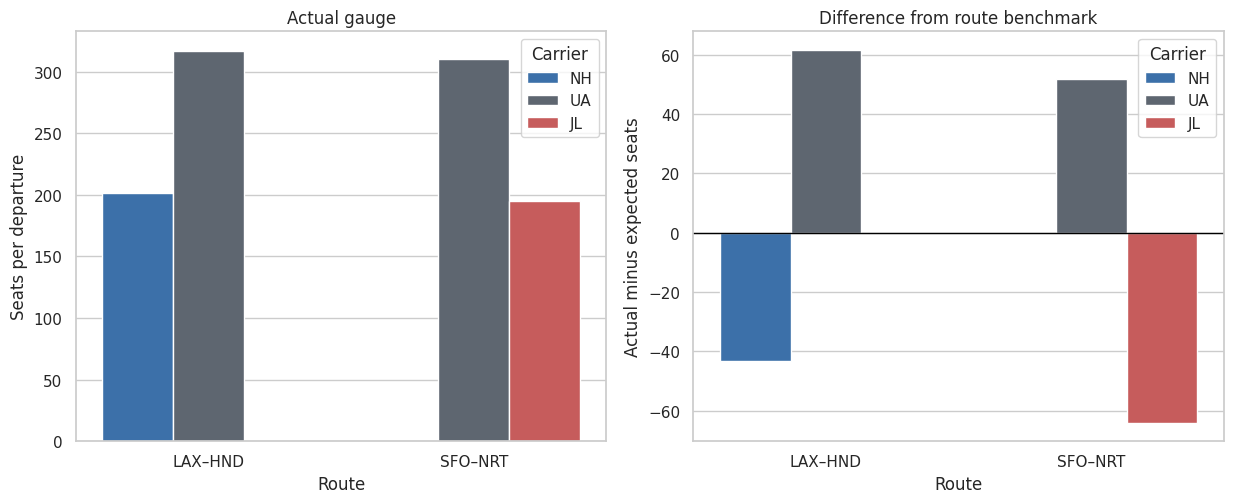

In [13]:
focus_robustness = focus_robustness.merge(
    focus_case_comparisons_2025[
        ["ROUTE", "UNIQUE_CARRIER", "passenger_load_factor", "passengers", "seats"]
    ],
    on=["ROUTE", "UNIQUE_CARRIER"],
    how="left",
    validate="one_to_one",
)

focus_display = focus_robustness[[
    "ROUTE", "UNIQUE_CARRIER", "departures", "actual_gauge",
    "gauge_residual", "gauge_residual_airline_adjusted",
    "passenger_load_factor", "passengers", "seats",
]].copy()
focus_display["daily_round_trips"] = focus_display["departures"] / 2 / 365
display(focus_display)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
sns.barplot(
    data=focus_display,
    x="ROUTE", y="actual_gauge", hue="UNIQUE_CARRIER",
    palette={"NH": "#2A6FBB", "JL": "#D84A4A", "UA": "#5B6573"},
    ax=axes[0],
)
axes[0].set(
    title="Actual gauge",
    xlabel="Route",
    ylabel="Seats per departure",
)
sns.barplot(
    data=focus_display,
    x="ROUTE", y="gauge_residual", hue="UNIQUE_CARRIER",
    palette={"NH": "#2A6FBB", "JL": "#D84A4A", "UA": "#5B6573"},
    ax=axes[1],
)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(
    title="Difference from route benchmark",
    xlabel="Route",
    ylabel="Actual minus expected seats",
)
for axis in axes:
    axis.legend(title="Carrier")
fig.tight_layout()
fig.savefig(assets_dir / "us_japan_focus_cases.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. Does measured freight change the comparison?

Fit both models on the same observations with at least 90% reliable-freight departure coverage. Adding log freight tonnes per departure is a descriptive sensitivity check; cargo can also respond to aircraft choice.

In [14]:
freight_model_panel = monthly_model_panel.loc[
    monthly_model_panel["freight_reliable_departure_share"].ge(0.90)
    & monthly_model_panel["freight_tonnes_per_departure"].notna()
].copy()
freight_model_panel["log1p_freight_tonnes_per_departure"] = np.log1p(
    freight_model_panel["freight_tonnes_per_departure"]
)

common_no_freight_model, common_no_freight_prediction, common_no_freight_metrics = (
    fit_weighted_gauge_model(
        freight_model_panel,
        BASE_CATEGORICAL,
        BASE_NUMERIC,
        "Reliable-freight subset without freight",
    )
)
freight_model, freight_prediction, freight_metrics = fit_weighted_gauge_model(
    freight_model_panel,
    BASE_CATEGORICAL,
    BASE_NUMERIC + ["log1p_freight_tonnes_per_departure"],
    "Reliable-freight subset with freight",
)

freight_model_panel["expected_gauge_without_freight"] = (
    common_no_freight_prediction
)
freight_model_panel["residual_without_freight"] = (
    freight_model_panel["seats_per_departure"]
    - freight_model_panel["expected_gauge_without_freight"]
)
freight_model_panel["expected_gauge_with_freight"] = freight_prediction
freight_model_panel["residual_with_freight"] = (
    freight_model_panel["seats_per_departure"]
    - freight_model_panel["expected_gauge_with_freight"]
)

freight_model_comparison = pd.DataFrame(
    [common_no_freight_metrics, freight_metrics]
)
freight_coefficients = coefficient_table(
    freight_model, "Reliable-freight subset with freight"
)

annual_common_without_freight = aggregate_expected_gauge(
    freight_model_panel,
    "expected_gauge_without_freight",
    "residual_without_freight",
)
annual_with_freight = aggregate_expected_gauge(
    freight_model_panel,
    "expected_gauge_with_freight",
    "residual_with_freight",
)

display(freight_model_comparison)
display(freight_coefficients)


# Compare focus-case residuals on the identical reliable-freight sample.
freight_focus = annual_common_without_freight.merge(
    annual_with_freight[["YEAR", "ROUTE", "UNIQUE_CARRIER", "gauge_residual"]],
    on=["YEAR", "ROUTE", "UNIQUE_CARRIER"], validate="one_to_one",
    suffixes=("_without_freight", "_with_freight"),
)
freight_focus = freight_focus.merge(
    focus_display[["ROUTE", "UNIQUE_CARRIER"]],
    on=["ROUTE", "UNIQUE_CARRIER"], validate="many_to_one",
).query("YEAR == 2025")
freight_focus = freight_focus[["ROUTE", "UNIQUE_CARRIER", "departures",
    "actual_gauge", "gauge_residual_without_freight", "gauge_residual_with_freight"]]
display(freight_focus)

,model,evaluation,observations,departures,weighted_r_squared,weighted_mae_seats,weighted_rmse_seats
0,Reliable-freight subset without freight,"In-sample, departure-weighted",7450,"269,291.000",0.664,24.117,32.776
1,Reliable-freight subset with freight,"In-sample, departure-weighted",7450,"269,291.000",0.667,23.902,32.596


,model,feature,coefficient_seats
0,Reliable-freight subset with freight,YEAR_CAT_2023,-7.620
1,Reliable-freight subset with freight,YEAR_CAT_2024,-3.109
2,Reliable-freight subset with freight,YEAR_CAT_2025,-4.087
3,Reliable-freight subset with freight,log_monthly_departures,-18.184
4,Reliable-freight subset with freight,log1p_freight_tonnes_per_departure,-7.643


,ROUTE,UNIQUE_CARRIER,departures,actual_gauge,gauge_residual_without_freight,gauge_residual_with_freight
10,LAX–HND,NH,"1,460.000",201.526,-42.309,-40.890
11,LAX–HND,UA,731.000,316.915,60.006,57.586
12,SFO–NRT,JL,730.000,194.921,-64.324,-62.786
13,SFO–NRT,UA,737.000,310.687,51.626,51.493


## 10. Interpretation and limits

Continental U.S.–Asia widebody departures and seats remain about 10% below 2019 in 2025, with similar average gauge. Carrier indicators improve in-sample fit, consistent with persistent fleet and cabin differences. ANA's LAX–HND case combines smaller gauge with more frequency; JAL's SFO–NRT case has substantially fewer seats per departure than United.

Official [JAL seat configurations](https://www.jal.co.jp/jp/en/aircraft/conf/787.html) include low-density 787-8 layouts. They make a premium-product explanation plausible, but do not establish the historical cabin mix, fare premium, or profitability of these specific route-months. Freight results are presented on a common sample so their incremental association can be evaluated directly.

Unobserved fares, cabin mix, connecting demand, slots, operating costs, and aircraft availability limit interpretation. Manual aircraft corrections and sample exclusions are assumptions with an audit trail. None of these models estimates optimal fleet allocation, causal demand effects, or profitability.

## 11. Export aggregate results

Save selected tables and the run summary. Original source records are not exported.

In [15]:
output_dir = RESULT_DIR
output_dir.mkdir(exist_ok=True)

final_tables = {
    "t100_input_summary.csv": audit["t100_inventory"],
    "sq_777_correction_log.csv": audit["sq_correction_summary"],
    "freighter_exclusions.csv": audit["freighter_exclusion_summary"],
    "unresolved_aircraft_pairs.csv": audit["suspicious_aircraft_pairs"],
    "known_valid_configurations.csv": audit["known_valid_aircraft_pairs"],
    "taiwan_parser_checks.csv": taiwan["tpe_quality"],
    "tpe_hkg_totals.csv": taiwan["tpe_hkg_total"],
    "freight_focus_cases.csv": freight_focus,
    "qc_summary.csv": audit["qc_summary"],
    "a350_to_a380_correction_log.csv": audit["a350_to_a380_log"],
    "annual_continental_market.csv": annual_continental,
    "aircraft_family_year.csv": family_year,
    "freight_reporting_audit.csv": audit["freight_reporting_audit"],
    "model_summary.csv": model_summary,
    "main_coefficients.csv": main_coefficients,
    "focus_case_comparisons_2025.csv": focus_display,
    "model_robustness_2025.csv": robustness_comparison_2025,
    "freight_model_comparison.csv": freight_model_comparison,
    "tpe_hkg_airline_year.csv": tpe_hkg_airline_year,
    "tpe_hkg_2019_vs_2025.csv": tpe_hkg_2019_vs_2025,
}
for filename, frame in final_tables.items():
    frame.to_csv(output_dir / filename, index=False)

run_summary = {
    "years": [2019, 2023, 2024, 2025],
    "market_model_observations": int(len(monthly_model_panel)),
    "market_model_routes": int(monthly_model_panel["ROUTE"].nunique()),
    "market_model_carriers": int(monthly_model_panel["UNIQUE_CARRIER"].nunique()),
    "market_model_weighted_r_squared": float(market_metrics["weighted_r_squared"]),
    "airline_adjusted_weighted_r_squared": float(airline_metrics["weighted_r_squared"]),
    "freight_incremental_r_squared": float(
        freight_metrics["weighted_r_squared"]
        - common_no_freight_metrics["weighted_r_squared"]
    ),
    "a350_to_a380_corrected_rows": int(panel["A350_TO_A380_CORRECTION"].sum()),
    "remaining_unresolved_rows_excluded": int(panel["UNRESOLVED_AIRCRAFT_PAIR"].sum()),
    "interpretation": "Descriptive benchmark, not an efficiency, profit, or causal model.",
}
(output_dir / "run_summary.json").write_text(
    json.dumps(run_summary, indent=2), encoding="utf-8"
)

print(f"Saved {len(final_tables)} aggregate tables to results/.")

Saved 20 aggregate tables to results/.
